WEATHER DATASET
 Day  Temperature  Humidity  Rainfall
   1           22        72         4
   2           23        70         0
   3           24        68         0
   4           23        74         6
   5           25        65         0
   6           26        63         0
   7           25        66         2
   8           27        60         0
   9           28        58         0
  10           27        61         1
  11           29        55         0
  12           30        52         0
  13           28        57         3
  14           29        54         0
  15           31        50         0
  16           32        48         0
  17           31        51         0
  18           30        53         2
  19           29        56         0
  20           28        59         4
  21           27        62         0
  22           26        66         1
  23           27        64         0
  24           25        69         7
  25           24        71       

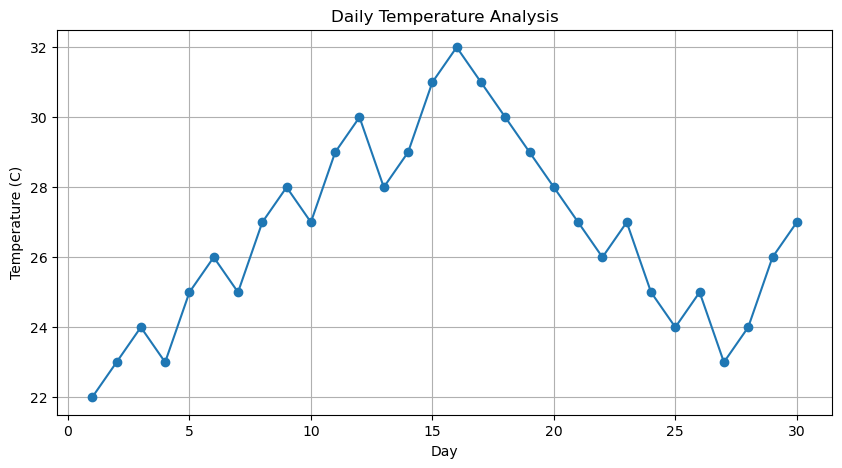

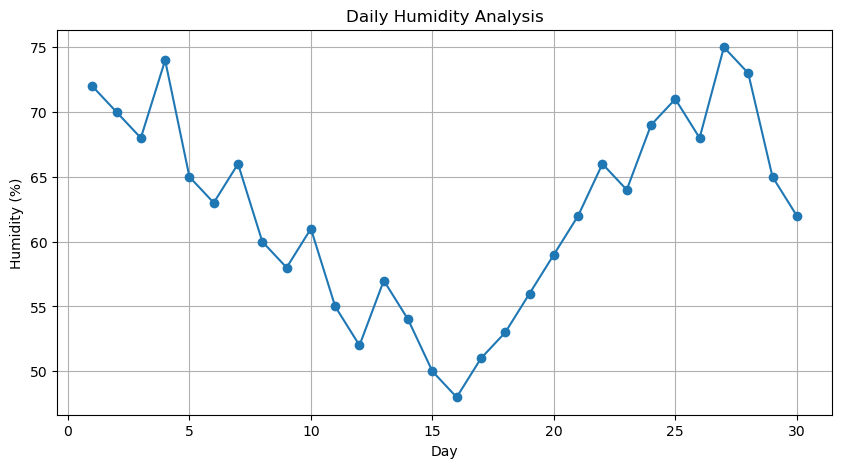

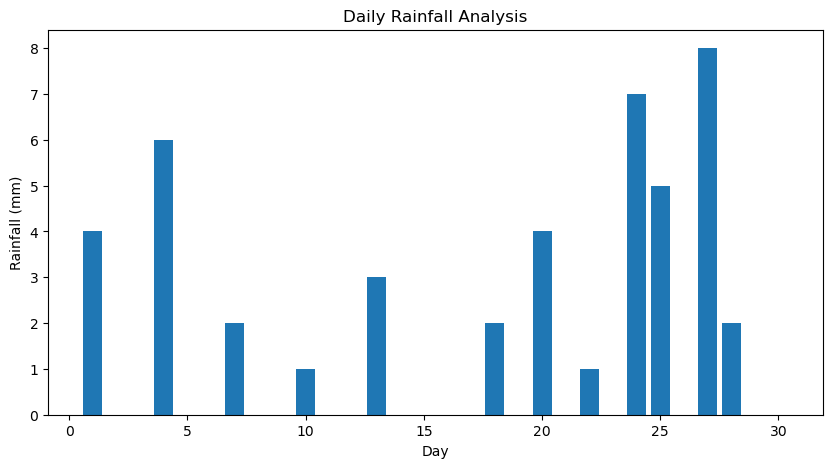

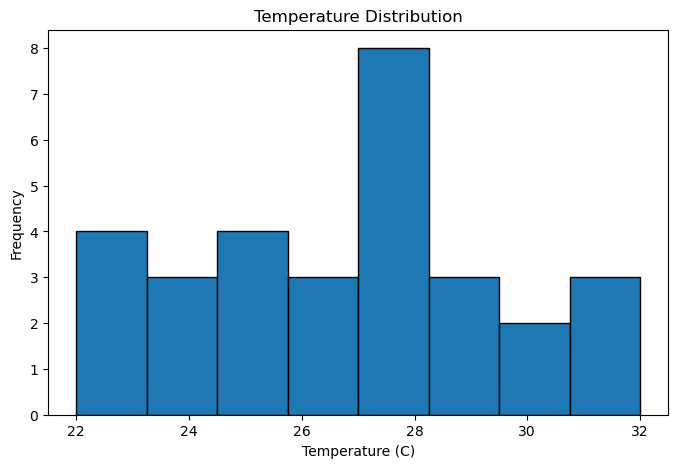


LINEAR REGRESSION RESULTS
-------------------------
Slope: 0.2087
Intercept: 24.558
MAE: 5.464
RMSE: 5.579
R2 Score: -16.238


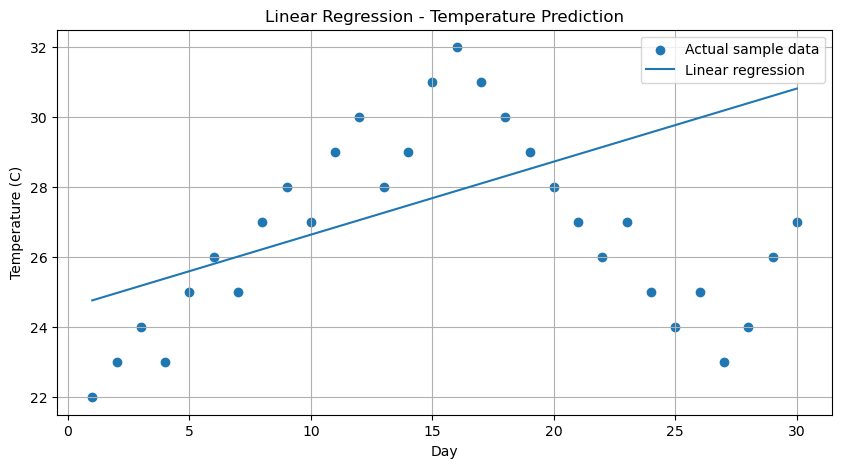


POLYNOMIAL REGRESSION RESULTS
-----------------------------
MAE: 3.032
RMSE: 4.146
R2 Score: -8.52


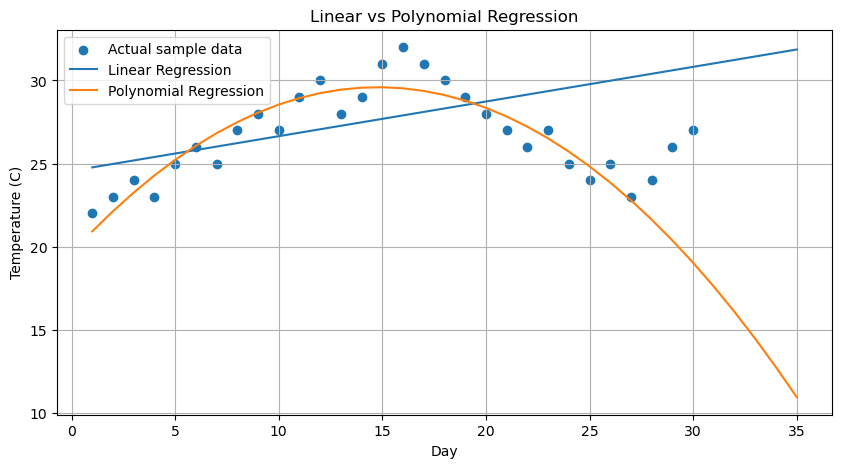


TEMPERATURE PREDICTION
----------------------
Day: 31
Linear prediction: 31.03 C
Polynomial prediction: 17.59 C

WEATHER CONDITIONS
20 C: Cool
26 C: Warm
32 C: Hot

PROJECT EXECUTION COMPLETED!


In [4]:
# WEATHER DATA ANALYSIS AND TEMPERATURE PREDICTION
# BCA Python and Machine Learning Project

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import json
import os

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------
# 1. CREATE WEATHER DATASET
# ------------------------------------------------

data = {
    "Day": np.arange(1, 31),
    "Temperature": [
        22, 23, 24, 23, 25, 26, 25, 27, 28, 27,
        29, 30, 28, 29, 31, 32, 31, 30, 29, 28,
        27, 26, 27, 25, 24, 25, 23, 24, 26, 27
    ],
    "Humidity": [
        72, 70, 68, 74, 65, 63, 66, 60, 58, 61,
        55, 52, 57, 54, 50, 48, 51, 53, 56, 59,
        62, 66, 64, 69, 71, 68, 75, 73, 65, 62
    ],
    "Rainfall": [
        4, 0, 0, 6, 0, 0, 2, 0, 0, 1,
        0, 0, 3, 0, 0, 0, 0, 2, 0, 4,
        0, 1, 0, 7, 5, 0, 8, 2, 0, 0
    ]
}

df = pd.DataFrame(data)

print("WEATHER DATASET")
print(df.to_string(index=False))

# ------------------------------------------------
# 2. SAVE CSV, TXT AND JSON FILES
# ------------------------------------------------

os.makedirs("weather_files", exist_ok=True)

df.to_csv("weather_files/weather.csv", index=False)

with open("weather_files/weather.txt", "w") as file:
    file.write("Weather Data Analysis Project\n")
    file.write(df.to_string(index=False))

with open("weather_files/weather.json", "w") as file:
    json.dump(df.to_dict(orient="records"), file, indent=4)

print("\nCSV, TXT and JSON files saved successfully!")

# Read CSV file
df = pd.read_csv("weather_files/weather.csv")

# Demonstrate missing-file error handling
try:
    with open("weather_files/missing.txt", "r") as file:
        print(file.read())
except FileNotFoundError:
    print("File not found. Error handled successfully.")

# ------------------------------------------------
# 3. STATISTICAL ANALYSIS
# ------------------------------------------------

print("\nWEATHER STATISTICS")
print("------------------")
print("Mean temperature:", round(df["Temperature"].mean(), 2))
print("Median temperature:", df["Temperature"].median())
print("Standard deviation:", round(df["Temperature"].std(), 2))
print("Maximum temperature:", df["Temperature"].max())
print("Minimum temperature:", df["Temperature"].min())
print("Average humidity:", round(df["Humidity"].mean(), 2))
print("Total rainfall:", df["Rainfall"].sum(), "mm")

# ------------------------------------------------
# 4. WEATHER GRAPHS
# ------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(df["Day"], df["Temperature"], marker="o")
plt.title("Daily Temperature Analysis")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(df["Day"], df["Humidity"], marker="o")
plt.title("Daily Humidity Analysis")
plt.xlabel("Day")
plt.ylabel("Humidity (%)")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(df["Day"], df["Rainfall"])
plt.title("Daily Rainfall Analysis")
plt.xlabel("Day")
plt.ylabel("Rainfall (mm)")
plt.show()

# Distribution graph
plt.figure(figsize=(8, 5))
plt.hist(df["Temperature"], bins=8, edgecolor="black")
plt.title("Temperature Distribution")
plt.xlabel("Temperature (C)")
plt.ylabel("Frequency")
plt.show()

# ------------------------------------------------
# 5. LINEAR REGRESSION MODEL
# ------------------------------------------------

X = df[["Day"]]
y = df["Temperature"]

# Keep the last 20% of days for testing
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("\nLINEAR REGRESSION RESULTS")
print("-------------------------")
print("Slope:", round(linear_model.coef_[0], 4))
print("Intercept:", round(linear_model.intercept_, 4))
print("MAE:", round(mean_absolute_error(y_test, linear_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_predictions)), 3))
print("R2 Score:", round(r2_score(y_test, linear_predictions), 3))

plt.figure(figsize=(10, 5))
plt.scatter(X, y, label="Actual sample data")
plt.plot(X, linear_model.predict(X), label="Linear regression")
plt.title("Linear Regression - Temperature Prediction")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# 6. POLYNOMIAL REGRESSION MODEL
# ------------------------------------------------

polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

polynomial_model.fit(X_train, y_train)
polynomial_predictions = polynomial_model.predict(X_test)

print("\nPOLYNOMIAL REGRESSION RESULTS")
print("-----------------------------")
print("MAE:", round(mean_absolute_error(y_test, polynomial_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, polynomial_predictions)), 3))
print("R2 Score:", round(r2_score(y_test, polynomial_predictions), 3))

plt.figure(figsize=(10, 5))
plt.scatter(X, y, label="Actual sample data")

days = pd.DataFrame({"Day": np.arange(1, 36)})

plt.plot(
    days["Day"],
    linear_model.predict(days),
    label="Linear Regression"
)

plt.plot(
    days["Day"],
    polynomial_model.predict(days),
    label="Polynomial Regression"
)

plt.title("Linear vs Polynomial Regression")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# 7. PREDICT TEMPERATURE FOR A NEW DAY
# ------------------------------------------------

new_day = pd.DataFrame({"Day": [31]})

linear_result = linear_model.predict(new_day)[0]
polynomial_result = polynomial_model.predict(new_day)[0]

print("\nTEMPERATURE PREDICTION")
print("----------------------")
print("Day:", 31)
print("Linear prediction:", round(linear_result, 2), "C")
print("Polynomial prediction:", round(polynomial_result, 2), "C")

# ------------------------------------------------
# 8. SIMPLE WEATHER CLASSIFICATION
# ------------------------------------------------

def weather_condition(temp):
    if temp >= 30:
        return "Hot"
    elif temp >= 25:
        return "Warm"
    else:
        return "Cool"

print("\nWEATHER CONDITIONS")
for temp in [20, 26, 32]:
    print(temp, "C:", weather_condition(temp))

print("\nPROJECT EXECUTION COMPLETED!")